# Full-Body Bending — Final Poses

A Gaussian pushing on segment 1 (`gauss_seg1`, s=1/3) and a linear spring pulling
the tip (`lin_seg3`, s=1.0), with both goals and both strengths set live from the
GUI. Each run in `outputs/body_shaping/` is one case, recorded with
`GUI_MultiVMC_Config_bending.py` under the name you gave `--run` (`bending_1`,
`bending_2`, ...).

Only the settled pose at the end of each run matters. This notebook finds every run
in the folder and draws the arm's actual shape as the motor encoders saw it (FK from
`q_motor`, not the virtual model's internal reference), averaged over the last few
seconds (`SETTLE_TAIL_S`): one figure with all runs overlaid, then one figure per
run. All figures share one axis range, so they compare directly.

How to record a case: see "Whole-body shaping" in `README.md`.

In [5]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))
sys.path.insert(0, os.path.abspath('../Kinematics'))
import glob
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from FK_Multi import FK_Multi
from plot_config import COLORS, FIG_W_SINGLE, FIG_W_DOUBLE, set_font_size

GRID = False
FONT_SIZE = 18
LEGEND_FONT_SIZE = FONT_SIZE * 0.75  # change to resize legend text only
set_font_size(FONT_SIZE, LEGEND_FONT_SIZE)

S_BACKBONE = np.linspace(0.0, 1.0, 25)  # s-samples along the arm for FK


def save_fig(fig, folder, name):
    """Every figure as PDF and SVG, next to the run it came from."""
    for ext in ('pdf', 'svg'):
        fig.savefig(os.path.join('outputs', folder, f'{name}.{ext}'))

## Load the runs

Every `.npz` in `outputs/body_shaping/` is picked up automatically — no list to
edit when you record a new case. Checkpoints (`.autosave`), truncated writes
(`.part`) and the `EXCLUDE` names are skipped; `ORDER` names the runs that go first
(this fixes their colors), the rest follow alphabetically.

K (tip spring) and A (Gaussian strength) are read from the run itself, not from the
config: they were tuned live in the GUI, so the recording is the only record of what
was used. Same for the goals.

In [6]:
FOLDER        = 'body_shaping'
SETTLE_TAIL_S = 3.0                     # [s] average the last this-many seconds as "the final pose"
ORDER         = ['bending_1', 'bending_2']  # runs listed first, in this order (fixes their colors)
EXCLUDE       = {'whole_body_shaping'}  # legacy run, recorded before the current config / log format


def list_runs(folder):
    """Every run in outputs/<folder>/ by name: ORDER first, the rest alphabetical."""
    names = []
    for path in glob.glob(os.path.join('outputs', folder, '*.npz')):
        name = os.path.splitext(os.path.basename(path))[0]
        if name.endswith('.part'):
            print(f'[skip] {name}.npz -- interrupted write, not readable')
        elif name.endswith('.autosave'):
            print(f'[skip] {name}.npz -- checkpoint of a run that did not exit cleanly')
        elif name not in EXCLUDE:
            names.append(name)
    first = [n for n in ORDER if n in names]
    return first + sorted(n for n in names if n not in first)


def backbone_of(q):
    """The arm's shape as the encoders see it: FK at S_BACKBONE for one motor vector."""
    return np.array([FK_Multi(q, s)[:3] for s in S_BACKBONE])


runs = {}
for name in list_runs(FOLDER):
    path = os.path.join('outputs', FOLDER, f'{name}.npz')
    try:
        d = np.load(path, allow_pickle=True)
        t    = d['t']
        tail = t >= t[-1] - SETTLE_TAIL_S   # "final pose" = mean over the last SETTLE_TAIL_S seconds
        comp_names = [str(n) for n in d['comp_names']]
        strength   = dict(zip(comp_names, d['k_params'][tail].mean(axis=0)))
        runs[name] = dict(
            path=path, duration=float(t[-1]),
            backbone=backbone_of(d['q_motor'][tail].mean(axis=0)),
            comp_names=comp_names, s_params=d['comp_s_params'],
            goal_final=d['goal'][tail].mean(axis=0),            # (N_VC, 3) [m]
            k_tip=float(strength.get('lin_seg3', np.nan)),      # linear spring stiffness [N/m]
            a_gauss=float(strength.get('gauss_seg1', np.nan)),  # Gaussian strength [N]
        )
    except Exception as exc:
        print(f'[skip] {name}.npz -- {type(exc).__name__}: {exc}')

if not runs:
    raise FileNotFoundError(f'No readable runs in outputs/{FOLDER}/ -- record a case first (see README.md).')


def goal_txt(r, comp):
    if comp not in r['comp_names']:
        return '-'
    g = r['goal_final'][r['comp_names'].index(comp)] * 100
    return f'({g[0]:6.1f}, {g[1]:6.1f}, {g[2]:6.1f})'


def run_label(name, r):
    return f"{name}  (K = {r['k_tip']:.0f} N/m, A = {r['a_gauss']:.0f} N)"


print(f'Final pose = mean of the last {SETTLE_TAIL_S:.1f} s of each run.  Goals in cm.\n')
print(f"{'run':<22}{'K tip':>8}{'A gauss':>9}   {'tip goal (x, y, z)':<26}{'gauss goal (x, y, z)':<26}{'run (s)':>8}")
for name, r in runs.items():
    print(f"{name:<22}{r['k_tip']:>8.0f}{r['a_gauss']:>9.0f}   "
          f"{goal_txt(r, 'lin_seg3'):<26}{goal_txt(r, 'gauss_seg1'):<26}{r['duration']:>8.1f}")

# One axis range for every figure below, pooled over all runs (backbones and
# goals), so each per-run figure compares directly with the others and with the
# overview.
pts    = np.vstack([np.vstack([r['backbone'], r['goal_final']]) for r in runs.values()]) * 100
pad_x  = 0.08 * np.ptp(pts[:, 0])
pad_z  = 0.08 * np.ptp(pts[:, 2])
XLIM   = (pts[:, 0].min() - pad_x, pts[:, 0].max() + pad_x)
ZLIM   = (pts[:, 2].min() - pad_z, pts[:, 2].max() + pad_z)

Final pose = mean of the last 3.0 s of each run.  Goals in cm.

run                      K tip  A gauss   tip goal (x, y, z)        gauss goal (x, y, z)       run (s)
bending_1                   50     2000   (  34.3,   -3.9,   43.5)  (   4.5,   -0.3,   14.5)     116.7
bending_2                   50     2000   ( -16.7,    1.6,   43.5)  (  -6.7,    1.9,   14.5)     151.4
bending_3                   50     1500   (  36.7,   -3.4,    0.0)  (   7.1,   -0.5,    8.9)     192.1
bending_4                   50     1500   (  38.0,   -7.4,    0.0)  (  -3.7,    0.5,   19.2)      94.6
bending_5                  100     1500   (   4.5,   -0.6,   41.7)  (   0.0,    0.0,   14.5)     110.3
bending_6                  100     1800   (   3.3,    0.2,   43.5)  (   1.5,    0.1,   14.5)     133.5


## All runs, overlaid

Side view (X-Z). Backbone color = run (top-left legend, with each run's K and A);
markers are black, deliberately not a backbone color, so they read clearly against
any line — shape = element (star = tip spring, circle = Gaussian), filled =
attachment point on the arm, open = that element's goal (bottom-right legend). The
gap between a filled and an open marker of the same shape is how far that
spring/Gaussian is still pulling.

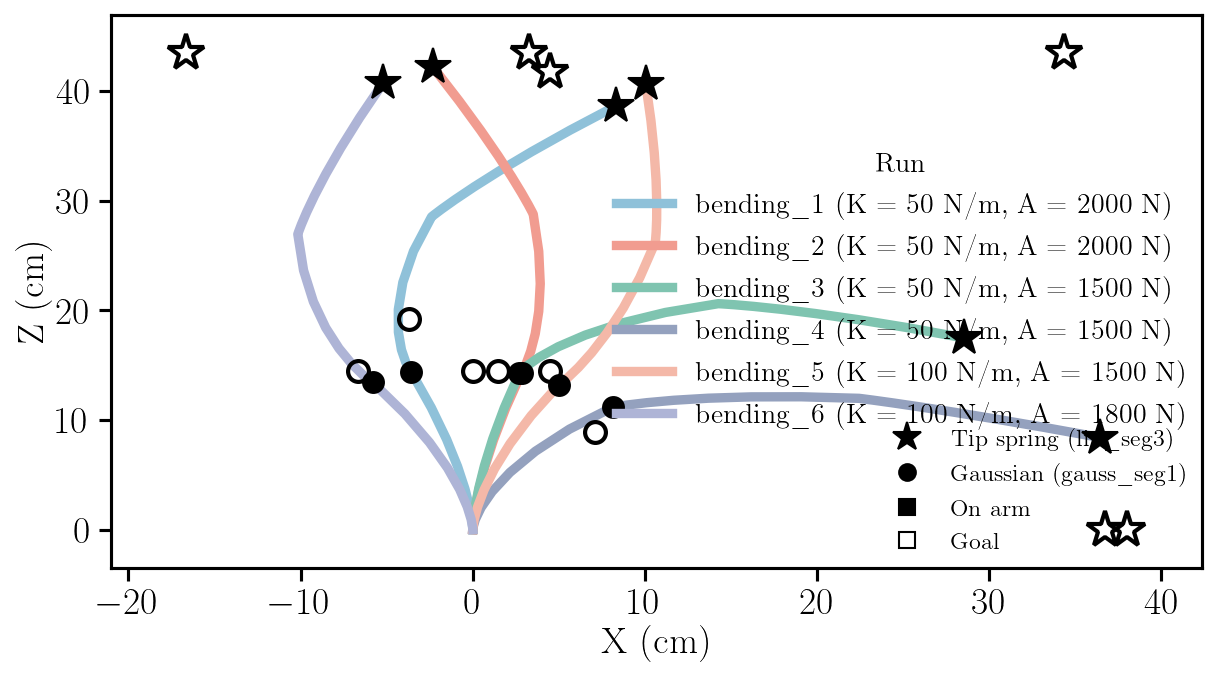

Saved → outputs/body_shaping/all_backbones.{pdf,svg}


In [7]:
# ---- style, shared by the overview and every per-run figure ----
FIG_W        = 8.0      # in -- TUNE THIS: total figure width
PANEL_ASPECT = 0.55     # TUNE THIS: panel height as a fraction of FIG_W
LINEWIDTH    = 4.5      # TUNE THIS: backbone line thickness
MARKER_COLOR = 'black'  # TUNE THIS: spring/goal marker color -- deliberately not a backbone color, so markers read clearly against any run's line
# TUNE THESE if a legend lands on data (a goal or an arm bent into its corner):
# any of 'upper/center/lower' + 'left/right'. Both figures use the same range, so
# a legend that is clear in one is clear in all -- unless a new run bends into it.
RUN_LEGEND_LOC   = 'center right'  # where the run legend goes
SHAPE_LEGEND_LOC = 'lower right'   # where the marker legend goes

SHAPE_HANDLES = [
    Line2D([0], [0], marker='*', color=MARKER_COLOR, markersize=14, linestyle='None', label='Tip spring (lin_seg3)'),
    Line2D([0], [0], marker='o', color=MARKER_COLOR, markersize=8, linestyle='None', label='Gaussian (gauss_seg1)'),
    Line2D([0], [0], marker='s', color=MARKER_COLOR, markersize=8, linestyle='None', markerfacecolor=MARKER_COLOR, label='On arm'),
    Line2D([0], [0], marker='s', color=MARKER_COLOR, markersize=8, linestyle='None', markerfacecolor='none', label='Goal'),
]


def draw_run(ax, r, color, label):
    """One run: thick backbone in `color`; each spring as a black marker,
    filled where it acts on the arm and open at its goal."""
    bb = r['backbone']
    ax.plot(bb[:, 0] * 100, bb[:, 2] * 100, color=color, linewidth=LINEWIDTH, zorder=3, label=label)
    for comp, s, g in zip(r['comp_names'], r['s_params'], r['goal_final']):
        p      = bb[np.argmin(np.abs(S_BACKBONE - s))]
        marker = '*' if comp == 'lin_seg3' else 'o'
        size   = 18 if comp == 'lin_seg3' else 10
        ax.plot(p[0] * 100, p[2] * 100, marker, color=MARKER_COLOR, markersize=size, zorder=4)
        ax.plot(g[0] * 100, g[2] * 100, marker, color=MARKER_COLOR, markersize=size, zorder=4,
                markerfacecolor='none', markeredgewidth=2.0)


def finish_axes(ax):
    ax.set_xlim(*XLIM)
    ax.set_ylim(*ZLIM)
    ax.set_xlabel('X (cm)')
    ax.set_ylabel('Z (cm)')
    ax.grid(GRID)
    # Two legends on the same axes -- add_artist keeps the first one when the
    # second .legend() call would otherwise replace it.
    run_legend = ax.legend(fontsize=LEGEND_FONT_SIZE, loc=RUN_LEGEND_LOC, framealpha=0.9, title='Run')
    ax.add_artist(run_legend)
    ax.legend(handles=SHAPE_HANDLES, fontsize=LEGEND_FONT_SIZE * 0.85, loc=SHAPE_LEGEND_LOC, framealpha=0.9)


# ---- overview: every run on one axes ----
fig, ax = plt.subplots(figsize=(FIG_W, FIG_W * PANEL_ASPECT), layout='constrained')
for i, (name, r) in enumerate(runs.items()):
    draw_run(ax, r, COLORS[i % len(COLORS)], run_label(name, r))
finish_axes(ax)

save_fig(fig, FOLDER, 'all_backbones')
plt.show()
print(f'Saved → outputs/{FOLDER}/all_backbones.{{pdf,svg}}')

## One figure per run

Same style, same axis range and same color per run as the overview, so a single
run's figure can be lined up against any other. Saved as `<run>_backbone.{pdf,svg}`.

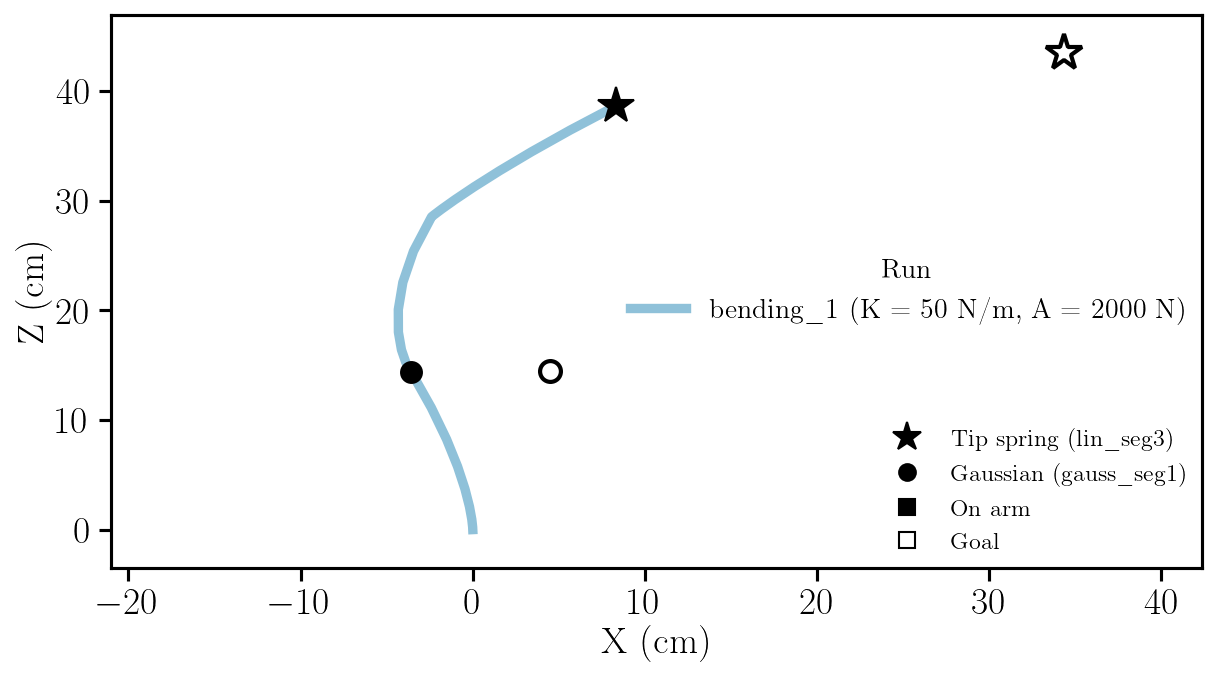

Saved → outputs/body_shaping/bending_1_backbone.{pdf,svg}


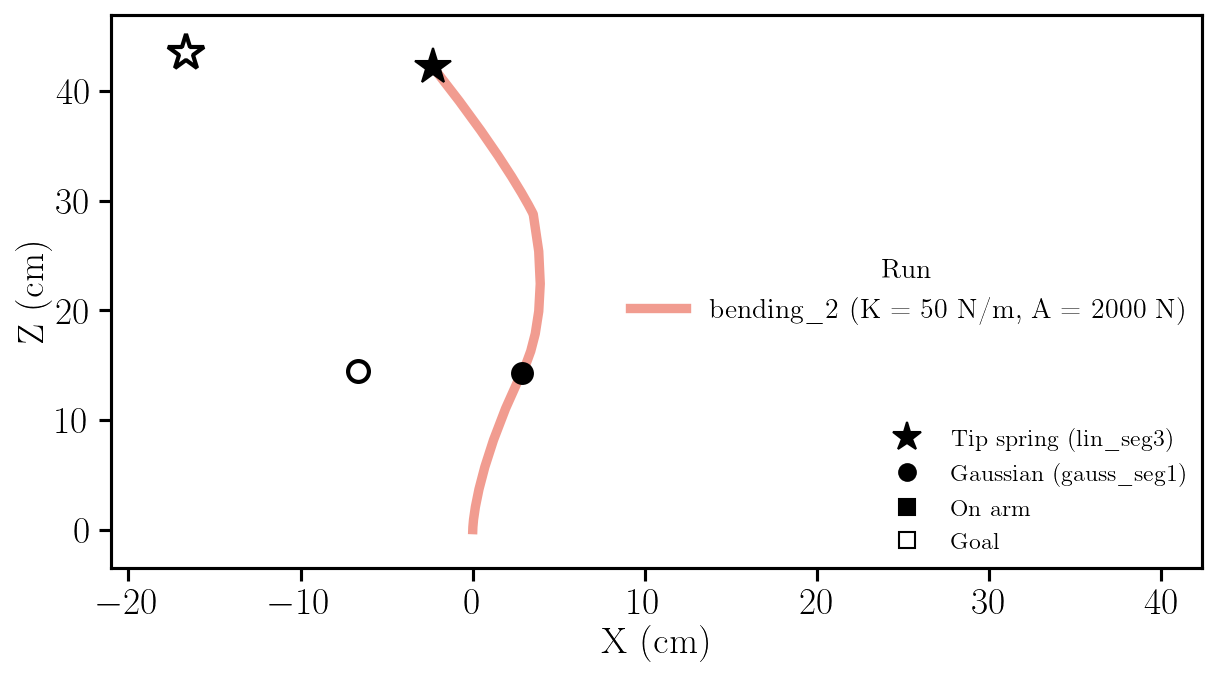

Saved → outputs/body_shaping/bending_2_backbone.{pdf,svg}


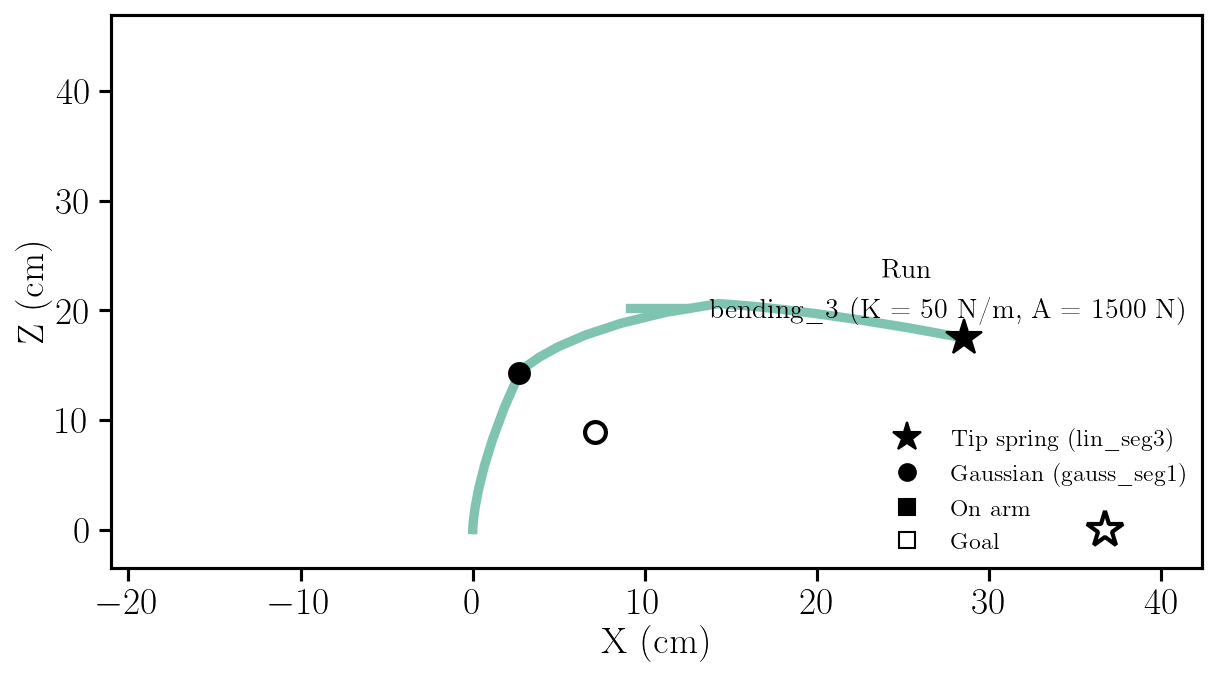

Saved → outputs/body_shaping/bending_3_backbone.{pdf,svg}


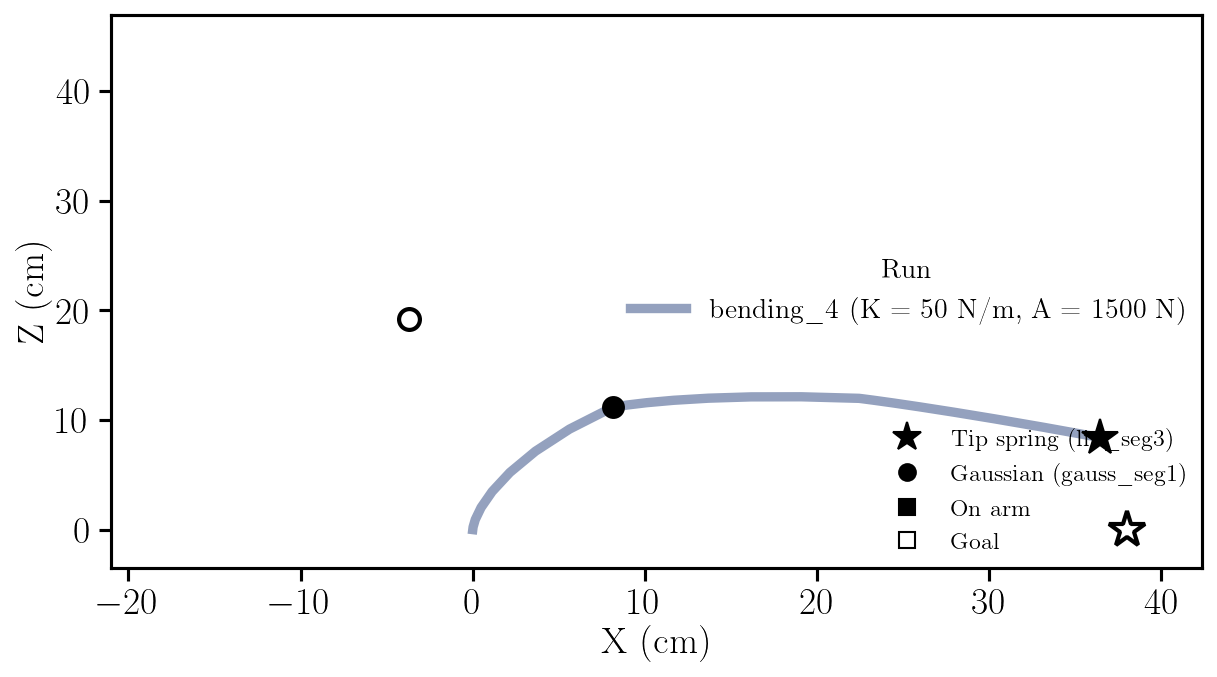

Saved → outputs/body_shaping/bending_4_backbone.{pdf,svg}


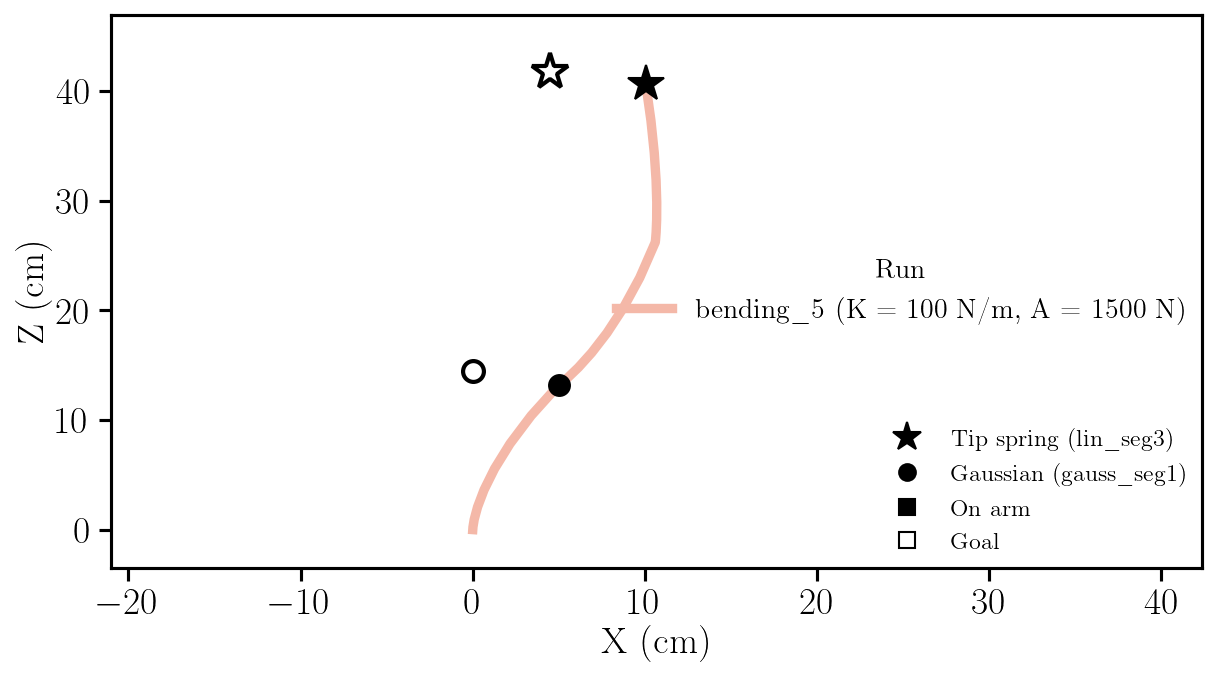

Saved → outputs/body_shaping/bending_5_backbone.{pdf,svg}


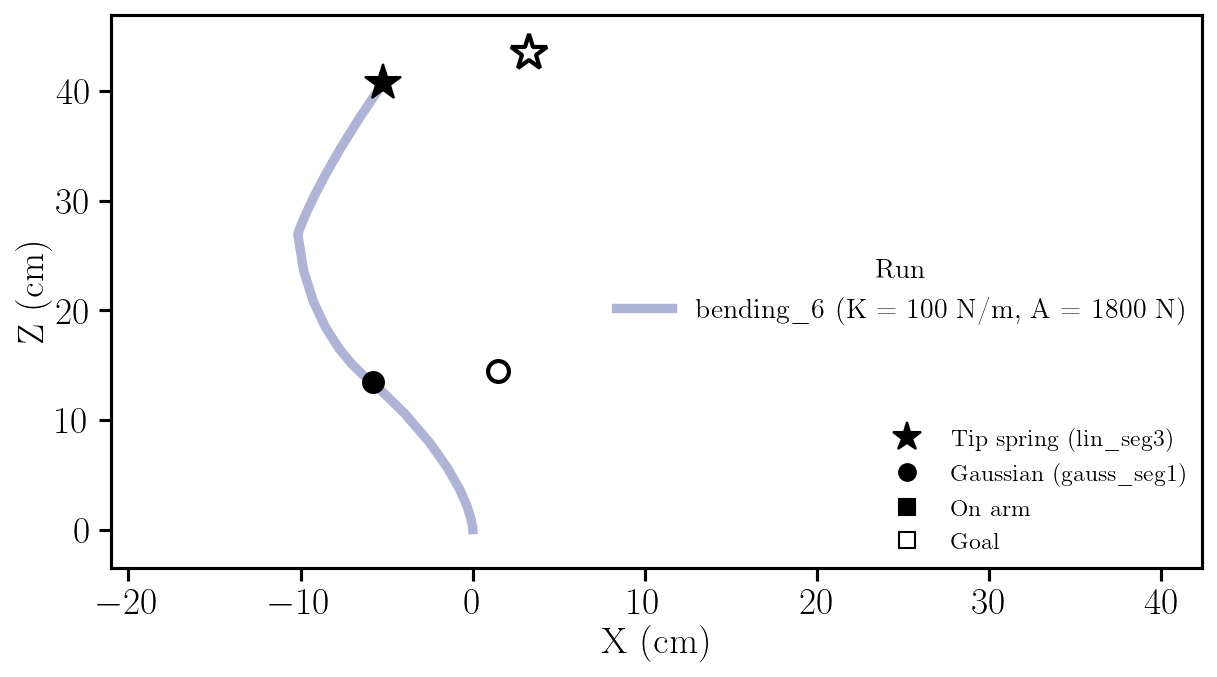

Saved → outputs/body_shaping/bending_6_backbone.{pdf,svg}


In [8]:
for i, (name, r) in enumerate(runs.items()):
    fig, ax = plt.subplots(figsize=(FIG_W, FIG_W * PANEL_ASPECT), layout='constrained')
    draw_run(ax, r, COLORS[i % len(COLORS)], run_label(name, r))
    finish_axes(ax)

    save_fig(fig, FOLDER, f'{name}_backbone')
    plt.show()
    print(f'Saved → outputs/{FOLDER}/{name}_backbone.{{pdf,svg}}')